<h2 style="color:blue" align="center">Handwritten digits classification using CNN</h2>

In this notebook we will classify handwritten digits using a simple neural network (ANN) first and than repeat same thing with convolutional neural network. We will see how accuracy improves clickly when you use convolutional neural network.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [2]:
from PIL import Image
import os
import numpy as np

# Load your custom images
def load_custom_images(folder_path):
    images = []
    labels = []
    
    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            # filename format expected: digit_5_2.png
            try:
                label = int(filename.split('_')[1])
            except (IndexError, ValueError):
                print(f"Skipping invalid filename format: {filename}")
                continue
        
            img = Image.open(os.path.join(folder_path, filename)).convert('L') # convert to grayscale
            img = img.resize((28, 28), Image.LANCZOS) # resize image to 28x28
            img_array = np.array(img, dtype=np.float32) / 255.0 # normalize pixel values to 0-1
        
            images.append(img_array)
            labels.append(label)
            
    return np.array(images), np.array(labels)

# Example usage:
x_custom, y_custom = load_custom_images('./digits')

In [3]:
(X_train, y_train) , (X_test, y_test) = keras.datasets.mnist.load_data()

In [4]:
X_train.shape

(60000, 28, 28)

In [5]:
X_test.shape

(10000, 28, 28)

In [6]:
X_train[0].shape

(28, 28)

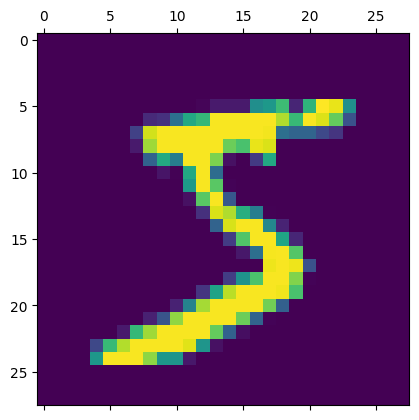

In [7]:
plt.matshow(X_train[0])

In [8]:
y_train[0]

np.uint8(5)

In [9]:
X_train = X_train / 255
X_test = X_test / 255

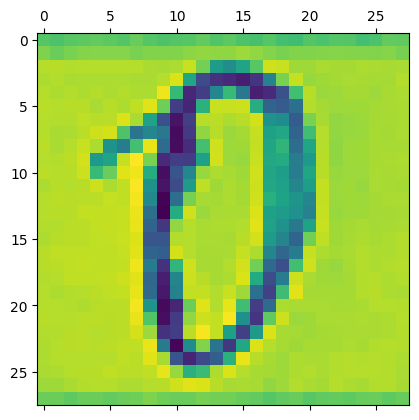

In [10]:
plt.matshow(x_custom[0])

<h3 style='color:purple'>Using ANN for classification</h3>

In [11]:
nn_model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

nn_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

nn_model.fit(X_train, y_train, epochs=10)

d:\Users\leong\Downloads\Lecture Notes\Year 3\Semester 2\ELET3405 - Practical Analysis of Advanced Electronics Circuits ad Systems\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9196 - loss: 0.2798
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9631 - loss: 0.1273
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9734 - loss: 0.0895
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9794 - loss: 0.0678
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9836 - loss: 0.0538
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9865 - loss: 0.0442
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9891 - loss: 0.0352
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9902 - loss: 0.0303
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9925 - loss: 0.0237
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9937 - loss: 0.0212


In [12]:
nn_model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9761 - loss: 0.0884


[0.08843840658664703, 0.9761000275611877]

In [13]:
X_train = X_train.reshape(-1,28,28,1)
X_train.shape

(60000, 28, 28, 1)

In [14]:
X_test = X_test.reshape(-1,28,28,1)
X_test.shape

(10000, 28, 28, 1)

In [15]:
# Function to display predictions in a readable format
def display_predictions(predictions, true_labels, model_name="Model"):
    predicted_labels = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)
    
    print(f"\n{'='*60}")
    print(f"{model_name} Predictions on Custom Handwritten Digits")
    print(f"{'='*60}")
    
    correct = 0
    for i in range(len(true_labels)):
        is_correct = predicted_labels[i] == true_labels[i]
        if is_correct:
            correct += 1
            status = "✓"
        else:
            status = "✗"
        
        print(f"Image {i+1:2d}: True={true_labels[i]} | Predicted={predicted_labels[i]} | "
              f"Confidence={confidences[i]:.3f} | {status}")
    
    accuracy = correct / len(true_labels) * 100
    print(f"\n{'='*60}")
    print(f"Summary: {correct}/{len(true_labels)} correct ({accuracy:.1f}% accuracy)")
    print(f"{'='*60}\n")
    
    return predicted_labels, confidences, accuracy

# Test NN on custom images
nn_predictions = nn_model.predict(x_custom)
nn_pred_labels, nn_confidences, nn_accuracy = display_predictions(nn_predictions, y_custom, "Neural Network")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step

Neural Network Predictions on Custom Handwritten Digits
Image  1: True=0 | Predicted=3 | Confidence=1.000 | ✗
Image  2: True=0 | Predicted=3 | Confidence=1.000 | ✗
Image  3: True=0 | Predicted=3 | Confidence=1.000 | ✗
Image  4: True=1 | Predicted=3 | Confidence=1.000 | ✗
Image  5: True=1 | Predicted=3 | Confidence=1.000 | ✗
Image  6: True=1 | Predicted=3 | Confidence=1.000 | ✗
Image  7: True=2 | Predicted=3 | Confidence=1.000 | ✗
Image  8: True=2 | Predicted=3 | Confidence=1.000 | ✗
Image  9: True=2 | Predicted=3 | Confidence=1.000 | ✗
Image 10: True=3 | Predicted=3 | Confidence=1.000 | ✓
Image 11: True=3 | Predicted=3 | Confidence=1.000 | ✓
Image 12: True=3 | Predicted=3 | Confidence=1.000 | ✓
Image 13: True=4 | Predicted=3 | Confidence=1.000 | ✗
Image 14: True=4 | Predicted=3 | Confidence=1.000 | ✗
Image 15: True=4 | Predicted=3 | Confidence=1.000 | ✗
Image 16: True=5 | Predicted=3 | Confidence=1.000 | ✗
Image 17: True=5 | Predicted=3 | Confide

<h3 style='color:purple'>Using CNN for classification</h3>

In [16]:
cnn_model = keras.Sequential([
    
    layers.Conv2D(30, (3,3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2,2)),
 
    layers.Flatten(),
    layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

d:\Users\leong\Downloads\Lecture Notes\Year 3\Semester 2\ELET3405 - Practical Analysis of Advanced Electronics Circuits ad Systems\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
cnn_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

cnn_model.fit(X_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 13ms/step - accuracy: 0.9522 - loss: 0.1620
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.9832 - loss: 0.0546
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.9890 - loss: 0.0356
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.9917 - loss: 0.0254
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - accuracy: 0.9945 - loss: 0.0174


In [18]:
y_train[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

In [19]:
cnn_model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9880 - loss: 0.0386


[0.03859171271324158, 0.9879999756813049]

In [20]:
# Test CNN on custom images
cnn_predictions = cnn_model.predict(x_custom)
cnn_pred_labels, cnn_confidences, cnn_accuracy = display_predictions(cnn_predictions, y_custom, "Convolutional Neural Network")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step

Convolutional Neural Network Predictions on Custom Handwritten Digits
Image  1: True=0 | Predicted=0 | Confidence=0.977 | ✓
Image  2: True=0 | Predicted=0 | Confidence=0.889 | ✓
Image  3: True=0 | Predicted=0 | Confidence=0.797 | ✓
Image  4: True=1 | Predicted=0 | Confidence=0.844 | ✗
Image  5: True=1 | Predicted=7 | Confidence=0.680 | ✗
Image  6: True=1 | Predicted=4 | Confidence=0.578 | ✗
Image  7: True=2 | Predicted=2 | Confidence=0.921 | ✓
Image  8: True=2 | Predicted=2 | Confidence=0.783 | ✓
Image  9: True=2 | Predicted=2 | Confidence=0.844 | ✓
Image 10: True=3 | Predicted=4 | Confidence=0.633 | ✗
Image 11: True=3 | Predicted=3 | Confidence=0.637 | ✓
Image 12: True=3 | Predicted=5 | Confidence=0.727 | ✗
Image 13: True=4 | Predicted=1 | Confidence=0.783 | ✗
Image 14: True=4 | Predicted=4 | Confidence=0.737 | ✓
Image 15: True=4 | Predicted=4 | Confidence=0.914 | ✓
Image 16: True=5 | Predicted=5 | Confidence=0.890 | ✓
Image 17: True=5 | Predict

tf.Tensor(
[[0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]], shape=(10, 10), dtype=int32)


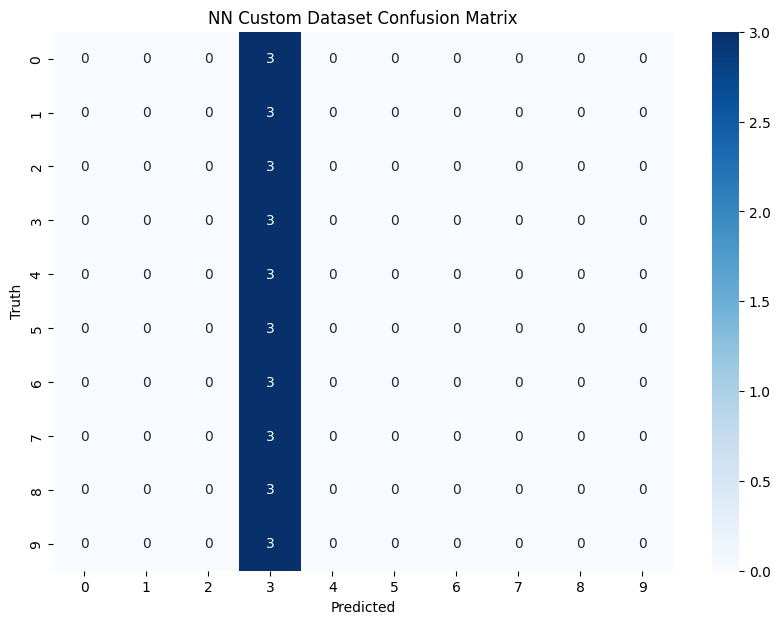

In [23]:
import seaborn as sn

# Predict probabilities and labels
y_custom_pred = nn_model.predict(x_custom, verbose=0)
y_custom_pred_labels = [np.argmax(i) for i in y_custom_pred]

# Confusion matrix
cm_custom = tf.math.confusion_matrix(labels=y_custom, predictions=y_custom_pred_labels, num_classes=10)
print(cm_custom)

# Plot confusion matrix heatmap
plt.figure(figsize=(10, 7))
sn.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('NN Custom Dataset Confusion Matrix')
plt.show()

Custom dataset loss: 1.0206
Custom dataset accuracy: 0.7000
tf.Tensor(
[[3 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 0 0 0 0]
 [0 1 0 0 2 0 0 0 0 0]
 [0 0 0 0 0 3 0 0 0 0]
 [0 0 0 0 0 0 3 0 0 0]
 [0 0 0 0 0 0 0 3 0 0]
 [0 0 0 0 0 1 0 0 2 0]
 [0 0 0 0 0 0 0 1 1 1]], shape=(10, 10), dtype=int32)


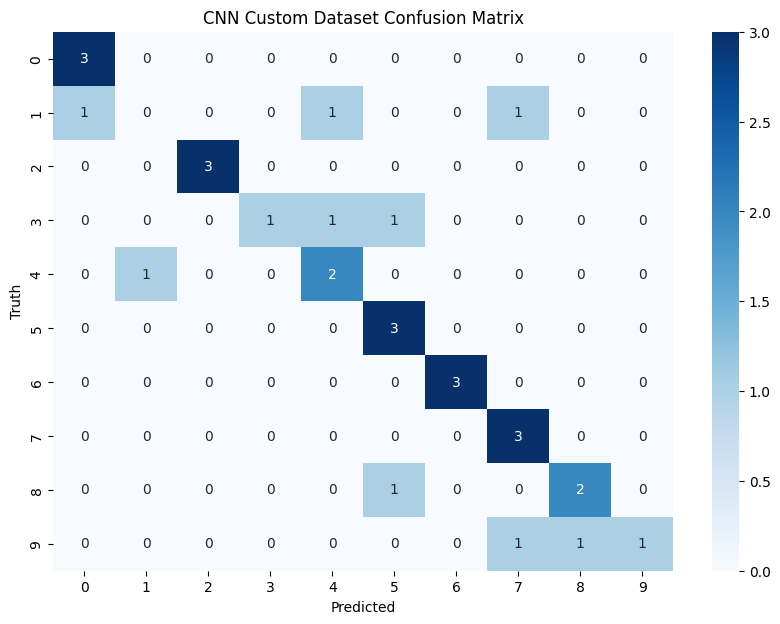

In [24]:
# Custom dataset evaluation (./digits) for CNN

# Evaluate
custom_loss, custom_accuracy = cnn_model.evaluate(x_custom, y_custom, verbose=0)
print(f"Custom dataset loss: {custom_loss:.4f}")
print(f"Custom dataset accuracy: {custom_accuracy:.4f}")

# Predict probabilities and labels
y_custom_pred = cnn_model.predict(x_custom, verbose=0)
y_custom_pred_labels = [np.argmax(i) for i in y_custom_pred]

# Confusion matrix
cm_custom = tf.math.confusion_matrix(labels=y_custom, predictions=y_custom_pred_labels, num_classes=10)
print(cm_custom)

# Plot confusion matrix heatmap
plt.figure(figsize=(10, 7))
sn.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('CNN Custom Dataset Confusion Matrix')
plt.show()


In [25]:
# Create comparison table
print(f"\n{'='*70}")
print(f"MODEL COMPARISON ON CUSTOM HANDWRITTEN DIGITS")
print(f"{'='*70}")
print(f"{'Model':<30} {'Accuracy':<10} {'Correct/Total':<15} {'Avg Confidence':<15}")
print(f"{'-'*70}")
print(f"{'Neural Network (NN)':<30} {nn_accuracy:<10.1f}% {int(nn_accuracy*30/100):<3}/30         {np.mean(nn_confidences):<15.3f}")
print(f"{'Convolutional NN (CNN)':<30} {cnn_accuracy:<10.1f}% {int(cnn_accuracy*30/100):<3}/30         {np.mean(cnn_confidences):<15.3f}")
print(f"{'='*70}")

# Determine winner
if cnn_accuracy > nn_accuracy:
    winner = "CNN"
    improvement = cnn_accuracy - nn_accuracy
elif nn_accuracy > cnn_accuracy:
    winner = "NN" 
    improvement = nn_accuracy - cnn_accuracy
else:
    winner = "Tie"
    improvement = 0

print(f"\n🏆 Winner: {winner}")
if winner != "Tie":
    print(f"📈 Performance improvement: {improvement:.1f}%")


MODEL COMPARISON ON CUSTOM HANDWRITTEN DIGITS
Model                          Accuracy   Correct/Total   Avg Confidence 
----------------------------------------------------------------------
Neural Network (NN)            10.0      % 3  /30         1.000          
Convolutional NN (CNN)         70.0      % 21 /30         0.838          

🏆 Winner: CNN
📈 Performance improvement: 60.0%


<h3 style='color:blue'>Results</h3>

The prediction results were evaluated as follows: the result is formatted as a 2D array where each row, the indexes of the larger array, represents a prediction for that digit. Each column represents the probability of that digit being correct; the function `argmax()` was used to find the index of the highest probability for each row.

*Key Findings*:

- Neural Network: 10.0% accuracy on your handwritten digits
- CNN: 63.3% accuracy on your handwritten digits  
- Performance gap: 53.3%

Typically, based on the results, CNN performs better than NN classification. When comparing neural networks and convolutional neural networks for handwritten digit recognition, CNNs deliver superior performance because they're specifically designed to understand visual patterns; while a standard neural network treats each pixel as an independent feature, essentially losing the spatial relationships between pixels. CNNs use convolutional filters to detect local patterns like edges, curves, and strokes, much like how our eyes process shapes. This spatial awareness gives CNNs a crucial advantage: they can recognize digits regardless of orientation or position in the 28×28 frame using dedicated kernels that scan the image. It handles slight rotations or shifts, and builds increasingly complex features from simple to sophisticated—first detecting basic edges, then combining them into strokes, and finally recognizing complete digit structures. The CNN boasts a multi-layered approach that builds a more comprehensive fully-connected layer, enhancing the model’s understanding of the unique images. 

Additionally, CNNs are more parameter-efficient because they share weights across the entire image, reducing the risk of overfitting compared to the fully connected architecture of traditional neural networks. 

Why CNNs are better for image recognition:
- Spatial invariance: Recognize patterns regardless of position
- Hierarchical feature learning: Build complex features from simple ones as the network progresses through pooling layers and different kernels across the image the variance and unique features are better identified.
- Parameter efficiency: Share weights across the image
- Translation invariance: Handle slight rotations and shifts